In [ ]:
"""
Graph Routing Cost-Probability Iteration Model
================================================
Input:  graph         - networkx DiGraph (or edge list)
        edges_length  - dict {edge: length}  (l_e)
        edges_vel     - dict {edge: velocity} (v_e)
        alpha         - congestion sensitivity parameter
        beta          - logit choice parameter (inverse temperature)

Output: edges_cost    - dict {edge: final cost c_e}
        edges_prob    - dict {edge: final probability p_e}

Dynamics:
  Initialisation:
    p_e(0)  = 1 / |E|   (uniform over edges)
    c_e(0)  = l_e/v_e + alpha * p_e(0)

  Iteration:
    1. Build Markov matrix PI  (column-stochastic, node × node)
         PI[i,j] = exp(-beta * c_{j->i}) / sum_k exp(-beta * c_{k->j})
       (rows = destination, columns = source)
    2. Add small teleportation to zero entries so PI is irreducible
    3. Compute stationary distribution pi of PI  (dominant eigenvector)
    4. Map node stationary distribution -> edge probability
         p_e(t+1) = pi[tail(e)] * PI[head(e), tail(e)]
         (probability of being on edge e = prob at its tail × transition prob)
    5. c_e(t+1) = l_e/v_e + alpha * p_e(t+1)
    6. Repeat until ||c(t+1) - c(t)||_inf < tol
"""

import numpy as np
import networkx as nx
from typing import Dict, Tuple, Union
import matplotlib.pyplot as plt


# ---------------------------------------------------------------------------
# Type aliases
# ---------------------------------------------------------------------------
Edge = Tuple  # (u, v) or (u, v, key)
EdgeDict = Dict[Edge, float]


# ---------------------------------------------------------------------------
# Core algorithm
# ---------------------------------------------------------------------------

def run_model(
    graph: nx.DiGraph,
    edges_length: EdgeDict,
    edges_vel: EdgeDict,
    alpha: float,
    beta: float,
    teleport: float = 1e-6,
    tol: float = 1e-8,
    max_iter: int = 1000,
    verbose: bool = True,
) -> Tuple[EdgeDict, EdgeDict]:
    """
    Run the cost-probability fixed-point iteration.

    Parameters
    ----------
    graph        : directed graph (networkx DiGraph)
    edges_length : {edge -> l_e}
    edges_vel    : {edge -> v_e}
    alpha        : weight on congestion term in cost
    beta         : logit sensitivity (higher = more deterministic)
    teleport     : small uniform mass added to zero off-diagonal entries
    tol          : convergence threshold (sup-norm on costs)
    max_iter     : maximum number of iterations
    verbose      : print iteration log

    Returns
    -------
    edges_cost   : {edge -> c_e}  at convergence
    edges_prob   : {edge -> p_e}  at convergence
    """

    edges = list(graph.edges())
    nodes = list(graph.nodes())
    n_edges = len(edges)
    n_nodes = len(nodes)

    if n_edges == 0:
        raise ValueError("Graph has no edges.")

    node_idx = {v: i for i, v in enumerate(nodes)}
    edge_idx = {e: i for i, e in enumerate(edges)}

    # Free-flow travel time for each edge
    free_flow = np.array([edges_length[e] / edges_vel[e] for e in edges])

    # ---- Initialisation ------------------------------------------------
    p = np.full(n_edges, 1.0 / n_edges)          # uniform edge probabilities
    c = free_flow + alpha * p                      # initial costs

    if verbose:
        print(f"{'Iter':>6}  {'max|Δc|':>12}  {'mean_c':>10}")
        print("-" * 34)

    for iteration in range(max_iter):
        c_old = c.copy()

        # ---- Build transition matrix PI (n_nodes × n_nodes) ------------
        # PI[i, j] = unnormalised weight for transition j -> i (edge j->i exists)
        PI = np.zeros((n_nodes, n_nodes))

        for e, ei in edge_idx.items():
            u, v = e[0], e[1]          # edge goes from u to v
            j = node_idx[u]            # source node index
            i = node_idx[v]            # destination node index
            PI[i, j] = np.exp(-beta * c[ei])

        # Normalise columns (outgoing from j)
        col_sums = PI.sum(axis=0)                  # shape (n_nodes,)
        nonzero_cols = col_sums > 0
        PI[:, nonzero_cols] /= col_sums[nonzero_cols]

        # Teleportation: add small uniform mass to zero entries
        # (ensures irreducibility / aperiodicity)
        zero_mask = (PI == 0)
        # Exclude self-loops already present and diagonal
        n_zero = zero_mask.sum(axis=0)             # zeros per column
        for j in range(n_nodes):
            if n_zero[j] > 0:
                PI[zero_mask[:, j], j] += teleport / n_zero[j]
        # Re-normalise after teleportation
        col_sums2 = PI.sum(axis=0)
        nonzero_cols2 = col_sums2 > 0
        PI[:, nonzero_cols2] /= col_sums2[nonzero_cols2]

        # ---- Stationary distribution (power iteration) -----------------
        pi = _stationary(PI)

        # ---- Map node probabilities to edge probabilities ---------------
        p_new = np.zeros(n_edges)
        for e, ei in edge_idx.items():
            u, v = e[0], e[1]
            j = node_idx[u]
            i = node_idx[v]
            p_new[ei] = pi[j] * PI[i, j]

        # Normalise so edge probs sum to 1
        p_sum = p_new.sum()
        if p_sum > 0:
            p_new /= p_sum

        # ---- Update costs -----------------------------------------------
        c = free_flow + alpha * p_new

        delta = np.max(np.abs(c - c_old))
        if verbose:
            print(f"{iteration+1:>6}  {delta:>12.2e}  {c.mean():>10.4f}")

        if delta < tol:
            if verbose:
                print(f"\nConverged in {iteration+1} iterations (Δc = {delta:.2e})")
            break
        p = p_new
    else:
        if verbose:
            print(f"\nWarning: did not converge within {max_iter} iterations.")

    # ---- Pack results into dicts ----------------------------------------
    edges_cost = {e: float(c[edge_idx[e]]) for e in edges}
    edges_prob = {e: float(p_new[edge_idx[e]]) for e in edges}

    return edges_cost, edges_prob


def _stationary(P: np.ndarray, n_iter: int = 10_000, eps: float = 1e-12) -> np.ndarray:
    """
    Compute stationary distribution of a column-stochastic matrix P
    via power iteration.
    """
    n = P.shape[0]
    pi = np.ones(n) / n
    for _ in range(n_iter):
        pi_new = P @ pi
        pi_new /= pi_new.sum()
        if np.max(np.abs(pi_new - pi)) < eps:
            break
        pi = pi_new
    return pi_new


# ---------------------------------------------------------------------------
# Convenience builder
# ---------------------------------------------------------------------------

def build_graph_from_edges(
    edge_list,               # list of (u, v) tuples
    lengths: dict,
    velocities: dict,
) -> Tuple[nx.DiGraph, EdgeDict, EdgeDict]:
    """
    Build a nx.DiGraph from an edge list plus length/velocity dicts.
    Lengths and velocities can be keyed by index or by (u,v) tuple.
    """
    G = nx.DiGraph()
    G.add_edges_from(edge_list)
    return G, lengths, velocities

In [64]:
# ---------------------------------------------------------------------------
# Demo / test
# ---------------------------------------------------------------------------

# ============================================================
# GRAPH GENERATION
# ============================================================

# np.random.seed(1)
G_grid = nx.grid_2d_graph(9, 9)
G = nx.convert_node_labels_to_integers(
    G_grid.to_directed(),
    label_attribute="coord",
)

# keep geometric positions from original grid coordinates
pos = {n: data["coord"] for n, data in G.nodes(data=True)}
edges = list(G.edges())
E = len(edges)
print(f"Nodes: {G.number_of_nodes()}, Edges: {E}")
expected_directed_edges = 2 * ((9 - 1) * 9 + 9 * (9 - 1))
missing_reverse_edges = [(u, v) for u, v in edges if not G.has_edge(v, u)]
print(f"Expected directed lattice edges: {expected_directed_edges}")
print(f"Missing reverse edges: {len(missing_reverse_edges)}")


# Single graph for car only
graphs = [G.copy()]
mode_names = ["car"]
mode_colors = {"car": "tab:red"}
mode_cmaps = {"car": plt.cm.Reds}
K = len(mode_names)  # K = 1

# ============================================================
# EDGE PARAMETERS
# ============================================================
lengths = np.ones(E) * 100.0  # uniform lengths for simplicity
n_lanes = np.ones(E, dtype=int)

car_speed = np.random.normal(loc=50.0 / 3.6, scale=5.0 / 3.6, size=E)
free_flow_speeds = car_speed.reshape(-1, 1)  # shape (E, 1)

alpha = 100
beta = 1.0
edges_length = {e: lengths[i] for i, e in enumerate(edges)}
edges_vel = {e: free_flow_speeds[i, 0] for i, e in enumerate(edges)}

print("=" * 50)
print("Graph Routing Cost-Probability Iteration Model")
print("=" * 50)
print(f"Nodes : {list(G.nodes())}")
print(f"Edges : {list(G.edges())}")
print(f"alpha = {alpha},  beta = {beta}\n")

costs, probs = run_model(
    graph=G,
    edges_length=edges_length,
    edges_vel=edges_vel,
    alpha=alpha,
    beta=beta,
    teleport=1e-6,
    tol=1e-9,
    max_iter=500,
    verbose=True,
)

print("\n--- Results ---")
print(f"{'Edge':<12} {'Cost c_e':>10} {'Prob p_e':>10}")
print("-" * 34)
for e in G.edges():
    print(f"{str(e):<12} {costs[e]:>10.5f} {probs[e]:>10.5f}")

print(f"\nSum of probabilities: {sum(probs.values()):.6f}")

Nodes: 81, Edges: 288
Expected directed lattice edges: 288
Missing reverse edges: 0
Graph Routing Cost-Probability Iteration Model
Nodes : [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80]
Edges : [(0, 9), (0, 1), (1, 10), (1, 0), (1, 2), (2, 11), (2, 1), (2, 3), (3, 12), (3, 2), (3, 4), (4, 13), (4, 3), (4, 5), (5, 14), (5, 4), (5, 6), (6, 15), (6, 5), (6, 7), (7, 16), (7, 6), (7, 8), (8, 17), (8, 7), (9, 0), (9, 18), (9, 10), (10, 1), (10, 19), (10, 9), (10, 11), (11, 2), (11, 20), (11, 10), (11, 12), (12, 3), (12, 21), (12, 11), (12, 13), (13, 4), (13, 22), (13, 12), (13, 14), (14, 5), (14, 23), (14, 13), (14, 15), (15, 6), (15, 24), (15, 14), (15, 16), (16, 7), (16, 25), (16, 15), (16, 17), (17, 8), (17, 26), (17, 16), (1

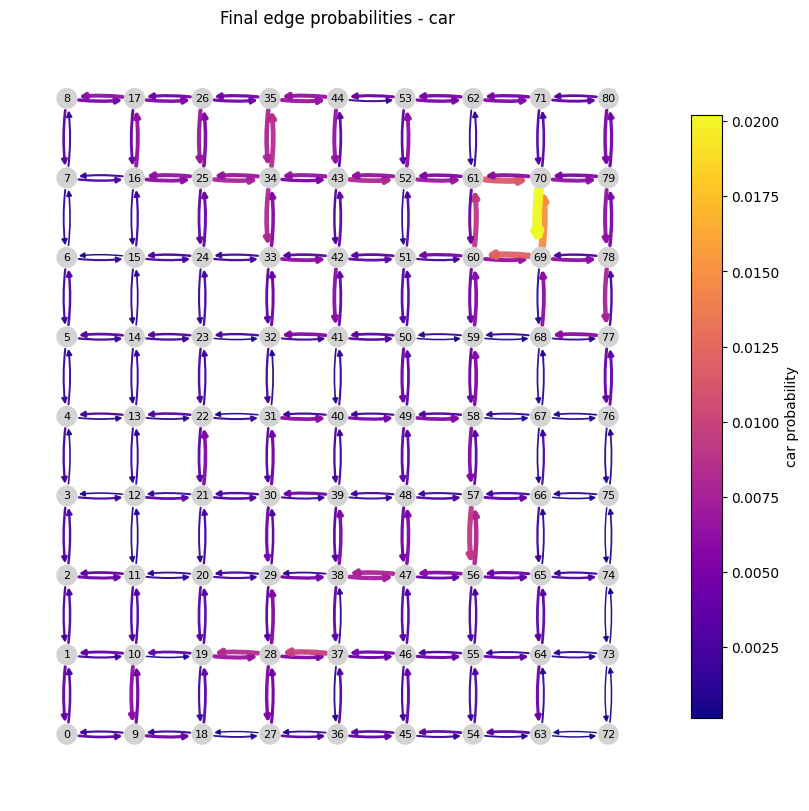

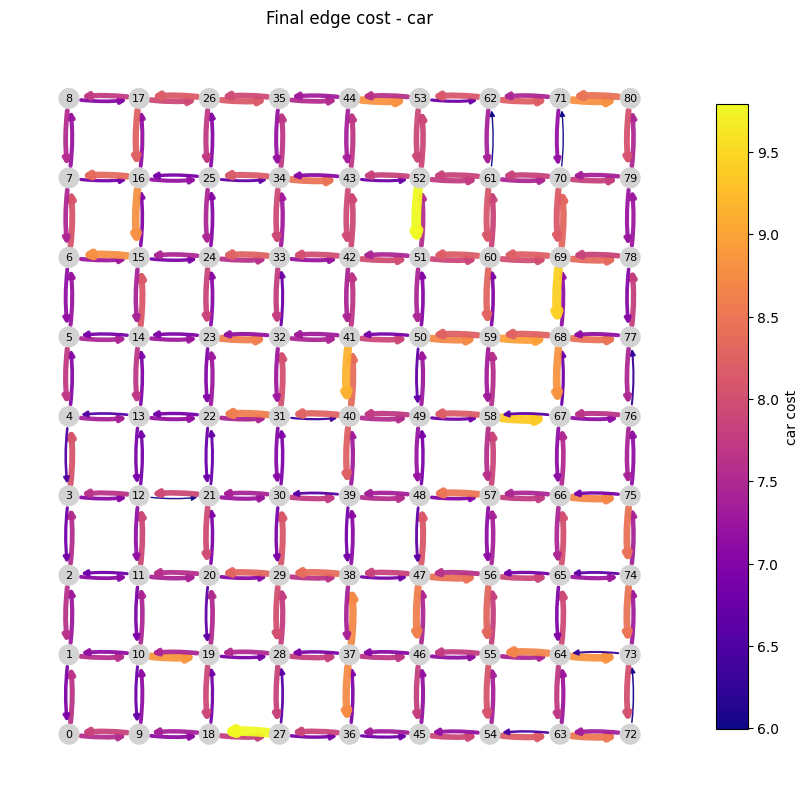


Top 5 edges by final probability:
  edge (70, 69) -> probability 0.02020
  edge (69, 70) -> probability 0.01476
  edge (69, 60) -> probability 0.01196
  edge (61, 70) -> probability 0.01163
  edge (37, 28) -> probability 0.00969

Bottom 5 edges by final cost:
  edge (70, 71) -> cost 5.99701
  edge (61, 62) -> cost 6.01204
  edge (12, 21) -> cost 6.01337
  edge (72, 73) -> cost 6.09154
  edge (73, 64) -> cost 6.28432


In [65]:
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np

# Choose a colormap that doesn't start with white/invisible colors
# Good alternatives: 'viridis', 'plasma', 'inferno', 'magma', 'Cividis'
chosen_cmap = "plasma"

# ============================================================
# PLOT: FINAL EDGE PROBABILITIES - CAR ONLY (single panel)
# ============================================================
edge_probs = np.array([probs[e] for e in edges])

fig, ax = plt.subplots(1, 1, figsize=(8, 8), constrained_layout=True)

norm = plt.Normalize(vmin=edge_probs.min(), vmax=edge_probs.max() + 1e-12)
edge_widths = 1.0 + 6.0 * norm(edge_probs)

# Color nodes: OD zones in orange, others in gray
node_colors = ["lightgray" for n in G.nodes()]
node_sizes = [200 for n in G.nodes()]

nx.draw_networkx_nodes(
    G, pos=pos, node_size=node_sizes, node_color=node_colors, ax=ax
)
nx.draw_networkx_labels(G, pos=pos, font_size=8, ax=ax)
nx.draw_networkx_edges(
    G,
    pos=pos,
    edgelist=edges,
    width=edge_widths,
    edge_color=edge_probs,
    edge_cmap=plt.get_cmap(chosen_cmap),  # Changed here
    alpha=0.95,
    arrows=True,
    arrowsize=8,
    connectionstyle="arc3,rad=0.08",
    ax=ax,
)

sm = plt.cm.ScalarMappable(cmap=plt.get_cmap(chosen_cmap), norm=norm)  # Changed here
plt.colorbar(sm, ax=ax, fraction=0.046, pad=0.04, label="car probability")
ax.set_title("Final edge probabilities - car")
ax.axis("off")
plt.show()

# ============================================================
# PLOT: FINAL EDGE COSTS - CAR ONLY (single panel)
# ============================================================
edge_costs = np.array([costs[e] for e in edges])

fig, ax = plt.subplots(1, 1, figsize=(8, 8), constrained_layout=True)

norm = plt.Normalize(vmin=edge_costs.min(), vmax=edge_costs.max() + 1e-12)
edge_widths = 1.0 + 6.0 * norm(edge_costs)

nx.draw_networkx_nodes(
    G, pos=pos, node_size=node_sizes, node_color=node_colors, ax=ax
)
nx.draw_networkx_labels(G, pos=pos, font_size=8, ax=ax)
nx.draw_networkx_edges(
    G,
    pos=pos,
    edgelist=edges,
    width=edge_widths,
    edge_color=edge_costs,
    edge_cmap=plt.get_cmap(chosen_cmap),  # Changed here
    alpha=0.95,
    arrows=True,
    arrowsize=8,
    connectionstyle="arc3,rad=0.08",
    ax=ax,
)

sm = plt.cm.ScalarMappable(cmap=plt.get_cmap(chosen_cmap), norm=norm)  # Changed here
plt.colorbar(sm, ax=ax, fraction=0.046, pad=0.04, label="car cost")
ax.set_title("Final edge cost - car")
ax.axis("off")
plt.show()

# ============================================================
# QUICK NUMERIC SUMMARY
# ============================================================
top_prob_edges = np.argsort(edge_probs)[-5:][::-1]
print("\nTop 5 edges by final probability:")
for idx in top_prob_edges:
    print(f"  edge {edges[idx]} -> probability {edge_probs[idx]:.5f}")

worst_cost_edges = np.argsort(edge_costs)[:5]
print("\nBottom 5 edges by final cost:")
for idx in worst_cost_edges:
    print(f"  edge {edges[idx]} -> cost {edge_costs[idx]:.5f}")


Correlation between edge probabilities and costs: -0.1590


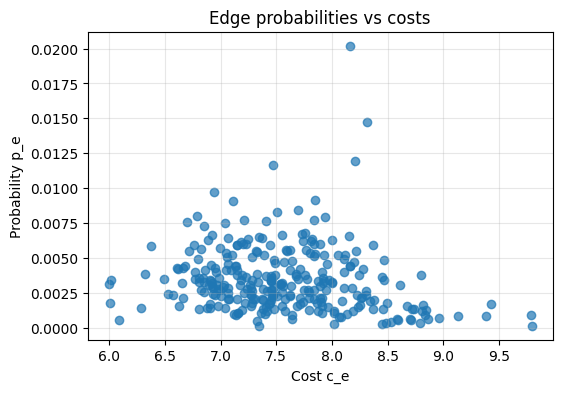

In [69]:
# check if probabilities and costs are correlated
correlation = np.corrcoef(edge_probs, edge_costs)[0, 1]
print(f"\nCorrelation between edge probabilities and costs: {correlation:.4f}")

# scatter plot of probabilities vs costs
plt.figure(figsize=(6, 4))
plt.scatter(edge_costs, edge_probs, alpha=0.7, color="tab:blue")
plt.title("Edge probabilities vs costs")    
plt.xlabel("Cost c_e")
plt.ylabel("Probability p_e")
plt.grid(True, alpha=0.3)
plt.show()

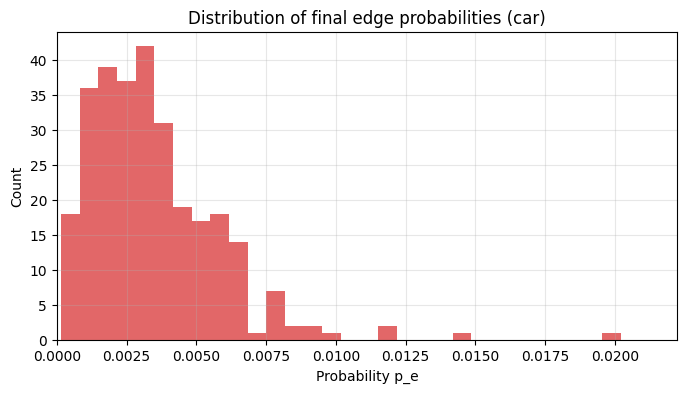

In [66]:
# plot the probabilities distribution
plt.figure(figsize=(8, 4))
plt.hist(edge_probs, bins=30, color='tab:red', alpha=0.7)
plt.title("Distribution of final edge probabilities (car)")
plt.xlabel("Probability p_e")
plt.ylabel("Count")
plt.grid(True, alpha=0.3)
plt.xlim(0, edge_probs.max() * 1.1)
plt.show()

Bologna extract: 1302 nodes, 2446 directed edges
Total directed edge length: 226.6 km
  Iter       max|Δc|      mean_c
----------------------------------
     1      3.10e-03     11.5350
     2      1.80e-06     11.5350
     3      2.65e-09     11.5350

Converged in 3 iterations (Δc = 2.65e-09)

Sum of Bologna edge probabilities: 1.000000
Bologna edge probability range: 1.19291e-56 - 0.0313513
Bologna edge cost range: 0.120 - 125.132

Top 10 Bologna edges by final probability:
  (252171070, 251844955): p=0.031351, cost=9.837, length=82 m, name=Via San Vitale
  (251844955, 252171070): p=0.030806, cost=9.837, length=82 m, name=Via San Vitale
  (342249196, 13513497274): p=0.028394, cost=1.178, length=16 m, name=Viale Antonio Aldini
  (13513497274, 342249196): p=0.028289, cost=1.178, length=16 m, name=Viale Antonio Aldini
  (2395514799, 2395514802): p=0.027492, cost=1.035, length=14 m, name=Viale Giovanni Gozzadini
  (252167330, 252167117): p=0.027486, cost=5.057, length=42 m, name=Via Inn

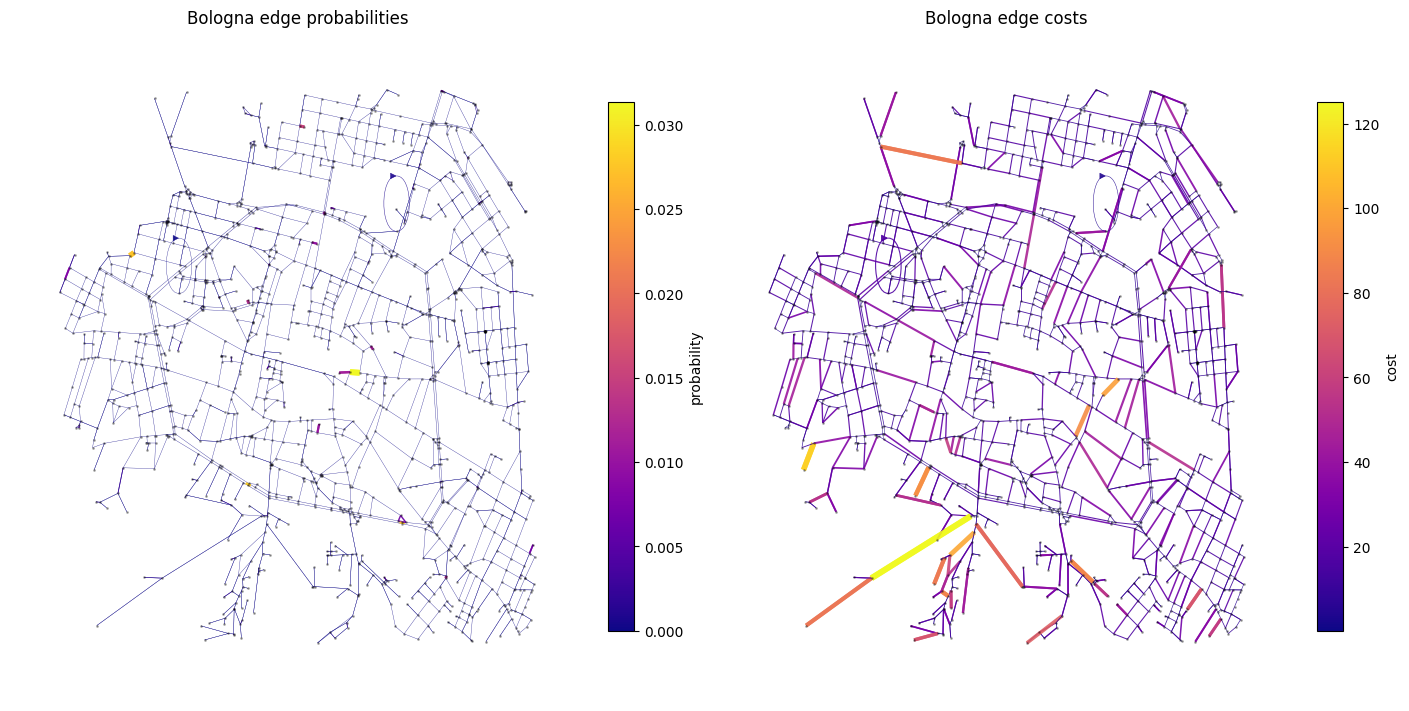

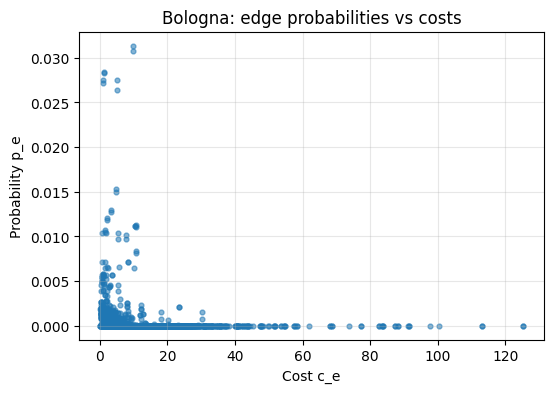

In [74]:
# try on real city graph (from OSMnx): Bologna
#
# The current algorithm builds a dense node x node transition matrix, so this
# cell intentionally uses a bounded central-city extract rather than the whole
# municipality.
try:
    import osmnx as ox
except ModuleNotFoundError as exc:
    raise ModuleNotFoundError(
        "This cell needs OSMnx. Install the project dependencies first, e.g. "
        "`uv sync` or `pip install osmnx`."
    ) from exc

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np

BOLOGNA_CENTER = (44.4949, 11.3426)  # Piazza Maggiore, (lat, lon)
BOLOGNA_DIST_M = 2000
URBAN_DEFAULT_SPEED_MPS = 30.0 / 3.6


def _parse_maxspeed_mps(value, default=URBAN_DEFAULT_SPEED_MPS):
    """Return maxspeed in m/s from common OSM maxspeed encodings."""
    if value is None:
        return default
    if isinstance(value, (list, tuple, set)):
        parsed = [_parse_maxspeed_mps(v, default=np.nan) for v in value]
        parsed = [v for v in parsed if np.isfinite(v)]
        return float(np.mean(parsed)) if parsed else default
    if isinstance(value, (int, float)):
        return float(value) / 3.6

    text = str(value).lower().strip()
    if not text:
        return default
    if "walk" in text or "signals" in text or "none" in text:
        return default

    import re

    numbers = [float(x) for x in re.findall(r"\d+(?:\.\d+)?", text)]
    if not numbers:
        return default
    speed = float(np.mean(numbers))
    if "mph" in text:
        return speed * 0.44704
    return speed / 3.6


def osmnx_multidigraph_to_digraph(G_multi):
    """Collapse parallel OSM edges, keeping the shortest geometry per direction."""
    G_simple = nx.DiGraph()

    for node, data in G_multi.nodes(data=True):
        G_simple.add_node(node, **{k: data[k] for k in ("x", "y") if k in data})

    best_edges = {}
    for u, v, data in G_multi.edges(data=True):
        length = float(data.get("length", 1.0))
        speed = _parse_maxspeed_mps(data.get("maxspeed"))
        edge_key = (u, v)

        if edge_key not in best_edges or length < best_edges[edge_key]["length"]:
            best_edges[edge_key] = {
                "length": max(length, 1.0),
                "speed_mps": max(speed, 1.0),
                "name": data.get("name", ""),
                "highway": data.get("highway", ""),
                "osmid": data.get("osmid", ""),
            }

    for (u, v), data in best_edges.items():
        G_simple.add_edge(u, v, **data)

    return G_simple


print("Downloading Bologna street graph from OpenStreetMap...")
G_osm = ox.graph_from_point(
    BOLOGNA_CENTER,
    dist=BOLOGNA_DIST_M,
    network_type="drive",
    simplify=True,
    retain_all=False,
)

G_bologna = osmnx_multidigraph_to_digraph(G_osm)

# Keep the largest strongly connected directed component so the Markov chain is
# not dominated by boundary one-way stubs.
largest_scc = max(nx.strongly_connected_components(G_bologna), key=len)
G_bologna = G_bologna.subgraph(largest_scc).copy()

edges_bologna = list(G_bologna.edges())
pos_bologna = {
    node: (data["x"], data["y"])
    for node, data in G_bologna.nodes(data=True)
}
edges_length_bologna = {
    edge: G_bologna.edges[edge]["length"]
    for edge in edges_bologna
}
edges_vel_bologna = {
    edge: G_bologna.edges[edge]["speed_mps"]
    for edge in edges_bologna
}

print(
    f"Bologna extract: {G_bologna.number_of_nodes()} nodes, "
    f"{G_bologna.number_of_edges()} directed edges"
)
print(
    f"Total directed edge length: "
    f"{sum(edges_length_bologna.values()) / 1000:.1f} km"
)

alpha_bologna = 0.1
beta_bologna = 1.0

costs_bologna, probs_bologna = run_model(
    graph=G_bologna,
    edges_length=edges_length_bologna,
    edges_vel=edges_vel_bologna,
    alpha=alpha_bologna,
    beta=beta_bologna,
    teleport=1e-6,
    tol=1e-7,
    max_iter=250,
    verbose=True,
)

edge_probs_bologna = np.array([probs_bologna[e] for e in edges_bologna])
edge_costs_bologna = np.array([costs_bologna[e] for e in edges_bologna])

print(f"\nSum of Bologna edge probabilities: {edge_probs_bologna.sum():.6f}")
print(
    "Bologna edge probability range: "
    f"{edge_probs_bologna.min():.6g} - {edge_probs_bologna.max():.6g}"
)
print(
    "Bologna edge cost range: "
    f"{edge_costs_bologna.min():.3f} - {edge_costs_bologna.max():.3f}"
)

print("\nTop 10 Bologna edges by final probability:")
for idx in np.argsort(edge_probs_bologna)[-10:][::-1]:
    edge = edges_bologna[idx]
    attrs = G_bologna.edges[edge]
    name = attrs.get("name") or "unnamed road"
    if isinstance(name, list):
        name = ", ".join(map(str, name[:2]))
    print(
        f"  {edge}: p={edge_probs_bologna[idx]:.6f}, "
        f"cost={edge_costs_bologna[idx]:.3f}, "
        f"length={attrs['length']:.0f} m, name={name}"
    )

# Plot probabilities and costs on the real street geometry.
fig, axes = plt.subplots(1, 2, figsize=(14, 7), constrained_layout=True)
for ax, values, title, label in [
    (axes[0], edge_probs_bologna, "Bologna edge probabilities", "probability"),
    (axes[1], edge_costs_bologna, "Bologna edge costs", "cost"),
]:
    norm = plt.Normalize(values.min(), values.max() + 1e-12)
    widths = 0.25 + 4.0 * norm(values)

    nx.draw_networkx_edges(
        G_bologna,
        pos=pos_bologna,
        edgelist=edges_bologna,
        edge_color=values,
        edge_cmap=plt.get_cmap("plasma"),
        width=widths,
        alpha=0.9,
        arrows=False,
        ax=ax,
    )
    nx.draw_networkx_nodes(
        G_bologna,
        pos=pos_bologna,
        node_size=1,
        node_color="black",
        alpha=0.3,
        ax=ax,
    )
    sm = plt.cm.ScalarMappable(cmap="plasma", norm=norm)
    plt.colorbar(sm, ax=ax, fraction=0.046, pad=0.04, label=label)
    ax.set_title(title)
    ax.axis("off")

plt.show()

plt.figure(figsize=(6, 4))
plt.scatter(edge_costs_bologna, edge_probs_bologna, s=12, alpha=0.55, color="tab:blue")
plt.title("Bologna: edge probabilities vs costs")
plt.xlabel("Cost c_e")
plt.ylabel("Probability p_e")
plt.grid(True, alpha=0.3)
plt.show()

